In [1]:
import torch
import torch.nn as nn

class DoubleConv(nn.Module):
    """(Convolution -> Batch Normalization -> ReLU) x 2"""
    def __init__(self, in_channels, out_channels):
        super(DoubleConv, self).__init__()
        self.double_conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.double_conv(x)


class UNet(nn.Module):
    def __init__(self, in_channels=3, out_channels=1):
        super(UNet, self).__init__()
        
        # 1. Encoder (Contracting Path)
        self.inc = DoubleConv(in_channels, 64)
        self.down1 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(64, 128))
        self.down2 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(128, 256))
        self.down3 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(256, 512))
        
        # 2. Bottleneck (Deepest Layer)
        self.bottleneck = nn.Sequential(nn.MaxPool2d(2), DoubleConv(512, 1024))
        
        # 3. Decoder (Expansive Path with Skip Connections)
        self.up1 = nn.ConvTranspose2d(1024, 512, kernel_size=2, stride=2)
        self.conv_up1 = DoubleConv(1024, 512)  # Concatenated channels: 512 (up) + 512 (skip) = 1024
        
        self.up2 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.conv_up2 = DoubleConv(512, 256)   # Concatenated channels: 256 + 256 = 512
        
        self.up3 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.conv_up3 = DoubleConv(256, 128)   # Concatenated channels: 128 + 128 = 256
        
        self.up4 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.conv_up4 = DoubleConv(128, 64)     # Concatenated channels: 64 + 64 = 128
        
        # 4. Final Output Projection Layer
        self.outc = nn.Conv2d(64, out_channels, kernel_size=1)
        
    def forward(self, x):
        # Forward pass through Encoder
        x1 = self.inc(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = self.down3(x3)
        
        # Bottleneck floor
        b = self.bottleneck(x4)
        
        # Decoder path stitching feature maps along dimension 1 (Channels)
        up1 = self.up1(b)
        merge1 = torch.cat([up1, x4], dim=1)
        out_up1 = self.conv_up1(merge1)
        
        up2 = self.up2(out_up1)
        merge2 = torch.cat([up2, x3], dim=1)
        out_up2 = self.conv_up2(merge2)
        
        up3 = self.up3(out_up2)
        merge3 = torch.cat([up3, x2], dim=1)
        out_up3 = self.conv_up3(merge3)
        
        up4 = self.up4(out_up3)
        merge4 = torch.cat([up4, x1], dim=1)
        out_up4 = self.conv_up4(merge4)
        
        # Output raw model logits
        logits = self.outc(out_up4)
        return logits

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = UNet(in_channels=3, out_channels=1).to(device)

print(f"Architecture successfully initialized!")
print(f"Target execution hardware device: {device}")


Architecture successfully initialized!
Target execution hardware device: cuda


In [2]:
# Create a dummy batch: 16 images, 3 color channels (RGB), 256x256 size
dummy_input = torch.randn(16, 3, 256, 256).to(device)

# Pass it through our initialized model on the GPU
with torch.no_grad():
    output_logits = model(dummy_input)

print(f"U-Net Input/Output Structural Diagnostic:")
print(f"Input batch shape sent to GPU:  {dummy_input.shape}")
print(f"Output mask shape back from GPU: {output_logits.shape}")


U-Net Input/Output Structural Diagnostic:
Input batch shape sent to GPU:  torch.Size([16, 3, 256, 256])
Output mask shape back from GPU: torch.Size([16, 1, 256, 256])


In [3]:
import torch.nn.functional as F

class BCEDiceLoss(nn.Module):
    def __init__(self, bce_weight=0.5):
        super(BCEDiceLoss, self).__init__()
        self.bce_weight = bce_weight

    def forward(self, pred_logits, targets):
        # 1. Compute standard Binary Cross Entropy
        bce = F.binary_cross_entropy_with_logits(pred_logits, targets)
        
        # 2. Compute Dice Coefficient Loss
        pred_probs = torch.sigmoid(pred_logits)
        
        # Flatten tensors to compute global intersection
        pred_flat = pred_probs.view(-1)
        target_flat = targets.view(-1)
        
        intersection = (pred_flat * target_flat).sum()
        dice_coef = (2.0 * intersection + 1e-5) / (pred_flat.sum() + target_flat.sum() + 1e-5)
        dice_loss = 1.0 - dice_coef
        
        # 3. Combine both losses
        return (self.bce_weight * bce) + ((1.0 - self.bce_weight) * dice_loss)

# Instantiate Loss and Optimizer objects
criterion = BCEDiceLoss(bce_weight=0.5)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

print("Loss Function: Combined BCE + Dice Loss Initialized.")
print("Optimizer: Adam configured with learning rate = 1e-4.")


Loss Function: Combined BCE + Dice Loss Initialized.
Optimizer: Adam configured with learning rate = 1e-4.


Found and verified 2594 matching image-mask pairs.

Launching Overfitting Test On Device: cuda...
Epoch [01/50] ---> Loss: 0.7152
Epoch [10/50] ---> Loss: 0.2195
Epoch [20/50] ---> Loss: 0.1702
Epoch [30/50] ---> Loss: 0.1481
Epoch [40/50] ---> Loss: 0.1312
Epoch [50/50] ---> Loss: 0.1161


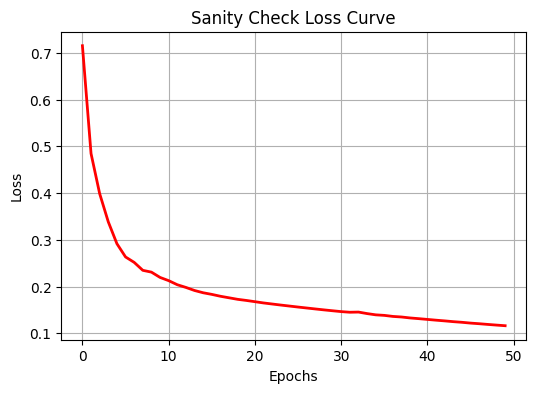

In [ ]:
import os
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import matplotlib.pyplot as plt

BASE_PATH = r"./dataset"
TRAIN_IMG_DIR = os.path.join(BASE_PATH, "ISIC2018_Task1-2_Training_Input")
TRAIN_MASK_DIR = os.path.join(BASE_PATH, "ISIC2018_Task1_Training_GroundTruth")
IMG_SIZE = (256, 256)

# Scan files manually from folders
img_files = sorted([f for f in os.listdir(TRAIN_IMG_DIR) if f.endswith('.jpg')])
mask_files = sorted([f for f in os.listdir(TRAIN_MASK_DIR) if f.endswith('.png')])

# Build verified pairs list based on matching IDs
paired_paths = []
for img_f in img_files:
    base_id = img_f.replace('.jpg', '')
    expected_mask = f"{base_id}_segmentation.png"
    if expected_mask in mask_files:
        paired_paths.append((
            os.path.join(TRAIN_IMG_DIR, img_f), 
            os.path.join(TRAIN_MASK_DIR, expected_mask)
        ))
print(f"Found and verified {len(paired_paths)} matching image-mask pairs.")

class ISICDataset(Dataset):
    def __init__(self, file_pairs, img_size=(256, 256)):
        self.file_pairs = file_pairs
        self.img_size = img_size

    def __len__(self):
        return len(self.file_pairs)

    def __getitem__(self, idx):
        img_path, mask_path = self.file_pairs[idx]
        
        # Load and normalize input image
        img = Image.open(img_path).convert('RGB').resize(self.img_size)
        img_np = np.array(img, dtype=np.float32) / 255.0
        img_tensor = torch.from_numpy(img_np).permute(2, 0, 1) # (Channels, H, W)
        
        # Load and normalize mask
        mask = Image.open(mask_path).convert('L').resize(self.img_size, resample=Image.NEAREST)
        mask_np = np.array(mask, dtype=np.float32) / 255.0
        mask_tensor = torch.from_numpy(mask_np).unsqueeze(0)   # (1, H, W)
        
        return img_tensor, mask_tensor

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Instantiating objects using our clean path list
full_dataset = ISICDataset(paired_paths, img_size=IMG_SIZE)
sanity_subset = torch.utils.data.Subset(full_dataset, range(5))
sanity_loader = DataLoader(sanity_subset, batch_size=5, shuffle=False)

# Pull single test batch
images, masks = next(iter(sanity_loader))
images, masks = images.to(device), masks.to(device)

# Initialize optimization layers
model = UNet(in_channels=3, out_channels=1).to(device)
criterion = BCEDiceLoss(bce_weight=0.5)
optimizer = torch.optim.Adam(model.parameters(), lr=5e-4)

epochs = 50
loss_history = []
model.train()

print(f"\nLaunching Overfitting Test On Device: {device}...")
for epoch in range(1, epochs + 1):
    optimizer.zero_grad()
    outputs = model(images)
    loss = criterion(outputs, masks)
    loss.backward()
    optimizer.step()
    
    loss_val = loss.item()
    loss_history.append(loss_val)
    if epoch % 10 == 0 or epoch == 1:
        print(f"Epoch [{epoch:02d}/{epochs}] ---> Loss: {loss_val:.4f}")

# Generate line plot window
plt.figure(figsize=(6, 4))
plt.plot(loss_history, color='red', lw=2)
plt.title('Sanity Check Loss Curve')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.grid(True)
plt.show()


Preparing 256x256 cached dataset across 8 CPU threads...
Cache ready (2594 pairs) in 0.2s!
Loaded 2594 cached pairs into RAM in 5.1s | Train: 2075 | Val: 519

Launching AMP-Accelerated Training Run (30 Epochs) on cuda...
---------------------------------------------------------------------------
Epoch [01/30] | Train Loss: 0.4328 | Val Loss: 0.3564 | Val Dice: 0.7551 | 143.82s [Saved Best]
Epoch [02/30] | Train Loss: 0.3187 | Val Loss: 0.3014 | Val Dice: 0.8117 | 86.20s [Saved Best]
Epoch [03/30] | Train Loss: 0.2756 | Val Loss: 0.2387 | Val Dice: 0.8431 | 86.88s [Saved Best]
Epoch [04/30] | Train Loss: 0.2368 | Val Loss: 0.2240 | Val Dice: 0.8281 | 83.71s
Epoch [05/30] | Train Loss: 0.2155 | Val Loss: 0.2067 | Val Dice: 0.8418 | 83.71s
Epoch [06/30] | Train Loss: 0.2064 | Val Loss: 0.2250 | Val Dice: 0.8144 | 83.42s
Epoch [07/30] | Train Loss: 0.1923 | Val Loss: 0.1734 | Val Dice: 0.8607 | 86.88s [Saved Best]
Epoch [08/30] | Train Loss: 0.1837 | Val Loss: 0.1955 | Val Dice: 0.8503 | 8

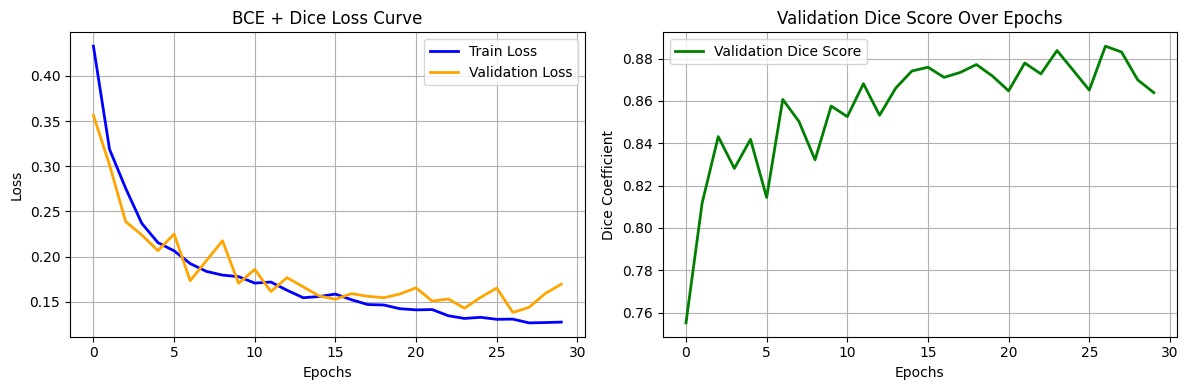

In [10]:
import random
import time
from concurrent.futures import ThreadPoolExecutor

# =====================================================================
# 1. ONE-TIME MULTI-THREADED 256x256 DISK CACHE (ZERO RAM BOTTLENECK)
# =====================================================================
BATCH_SIZE = 16
EPOCHS = 30
LEARNING_RATE = 2e-4
TRAIN_SPLIT = 0.8

CACHE_IMG_DIR = os.path.join(BASE_PATH, "cache_256_img")
CACHE_MSK_DIR = os.path.join(BASE_PATH, "cache_256_msk")
os.makedirs(CACHE_IMG_DIR, exist_ok=True)
os.makedirs(CACHE_MSK_DIR, exist_ok=True)

def resize_and_cache(pair):
    img_path, mask_path = pair
    out_img = os.path.join(CACHE_IMG_DIR, os.path.basename(img_path))
    out_msk = os.path.join(CACHE_MSK_DIR, os.path.basename(mask_path))

    if not os.path.exists(out_img):
        Image.open(img_path).convert('RGB').resize(IMG_SIZE).save(out_img, quality=95)
    if not os.path.exists(out_msk):
        Image.open(mask_path).convert('L').resize(IMG_SIZE, resample=Image.NEAREST).save(out_msk)
    return (out_img, out_msk)

print("Preparing 256x256 cached dataset across 8 CPU threads...")
t0 = time.time()
with ThreadPoolExecutor(max_workers=8) as ex:
    cached_pairs = list(ex.map(resize_and_cache, paired_paths))
print(f"Cache ready ({len(cached_pairs)} pairs) in {time.time() - t0:.1f}s!")

# =====================================================================
# 2. FAST PRE-ALLOCATED RAM LOAD FROM 256x256 CACHE (~3 SECONDS)
# =====================================================================
random.seed(42)
random.shuffle(cached_pairs)

N = len(cached_pairs)
split_idx = int(N * TRAIN_SPLIT)

X_data = np.empty((N, 3, *IMG_SIZE), dtype=np.float32)
Y_data = np.empty((N, 1, *IMG_SIZE), dtype=np.float32)

t_ram = time.time()
for idx, (img_p, msk_p) in enumerate(cached_pairs):
    X_data[idx] = np.asarray(Image.open(img_p), dtype=np.float32).transpose(2, 0, 1) / 255.0
    Y_data[idx, 0] = np.asarray(Image.open(msk_p), dtype=np.float32) / 255.0

train_X, val_X = torch.from_numpy(X_data[:split_idx]), torch.from_numpy(X_data[split_idx:])
train_Y, val_Y = torch.from_numpy(Y_data[:split_idx]), torch.from_numpy(Y_data[split_idx:])
print(f"Loaded {N} cached pairs into RAM in {time.time() - t_ram:.1f}s | Train: {len(train_X)} | Val: {len(val_X)}")

class RAMDataset(Dataset):
    def __init__(self, X, Y): self.X, self.Y = X, Y
    def __len__(self): return len(self.X)
    def __getitem__(self, idx): return self.X[idx], self.Y[idx]

train_loader = DataLoader(RAMDataset(train_X, train_Y), batch_size=BATCH_SIZE, shuffle=True, pin_memory=True)
val_loader   = DataLoader(RAMDataset(val_X, val_Y), batch_size=BATCH_SIZE, shuffle=False, pin_memory=True)

# =====================================================================
# 3. AMP-ACCELERATED TRAINING & VALIDATION LOOP (TENSOR CORES ENABLED)
# =====================================================================
torch.backends.cudnn.benchmark = True

def compute_dice_score(pred_logits, targets, threshold=0.5):
    preds = (torch.sigmoid(pred_logits) > threshold).float()
    intersection = (preds * targets).sum()
    return ((2.0 * intersection + 1e-5) / (preds.sum() + targets.sum() + 1e-5)).item()

model = UNet(in_channels=3, out_channels=1).to(device)
criterion = BCEDiceLoss(bce_weight=0.5)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
scaler = torch.amp.GradScaler('cuda')

train_loss_history, val_loss_history, val_dice_history = [], [], []
best_val_dice = 0.0

print(f"\nLaunching AMP-Accelerated Training Run ({EPOCHS} Epochs) on {device}...")
print("-" * 75)
global_start = time.time()

for epoch in range(1, EPOCHS + 1):
    epoch_start = time.time()

    # --- Train (with FP16/BF16 Tensor Cores) ---
    model.train()
    running_train_loss = 0.0
    for imgs, msks in train_loader:
        imgs, msks = imgs.to(device, non_blocking=True), msks.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast('cuda'):
            outputs = model(imgs)
            loss = criterion(outputs, msks)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        running_train_loss += loss.item()

    avg_train_loss = running_train_loss / len(train_loader)
    train_loss_history.append(avg_train_loss)

    # --- Validate ---
    model.eval()
    running_val_loss, running_val_dice = 0.0, 0.0
    with torch.no_grad():
        for imgs, msks in val_loader:
            imgs, msks = imgs.to(device, non_blocking=True), msks.to(device, non_blocking=True)
            with torch.amp.autocast('cuda'):
                outputs = model(imgs)
                running_val_loss += criterion(outputs, msks).item()
                running_val_dice += compute_dice_score(outputs, msks)

    avg_val_loss = running_val_loss / len(val_loader)
    avg_val_dice = running_val_dice / len(val_loader)
    val_loss_history.append(avg_val_loss)
    val_dice_history.append(avg_val_dice)

    saved_flag = ""
    if avg_val_dice > best_val_dice:
        best_val_dice = avg_val_dice
        torch.save(model.state_dict(), "best_isic_unet.pth")
        saved_flag = " [Saved Best]"

    elapsed = time.time() - epoch_start
    print(
        f"Epoch [{epoch:02d}/{EPOCHS}] | "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Val Loss: {avg_val_loss:.4f} | "
        f"Val Dice: {avg_val_dice:.4f} | "
        f"{elapsed:.2f}s{saved_flag}"
    )

print("-" * 75)
print(f"Training Complete in {time.time() - global_start:.1f}s | Best Validation Dice: {best_val_dice:.4f}")

# =====================================================================
# 4. PLOT TRAINING & VALIDATION CURVES
# =====================================================================
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(train_loss_history, label='Train Loss', color='blue', lw=2)
axes[0].plot(val_loss_history, label='Validation Loss', color='orange', lw=2)
axes[0].set_title('BCE + Dice Loss Curve')
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True)

axes[1].plot(val_dice_history, label='Validation Dice Score', color='green', lw=2)
axes[1].set_title('Validation Dice Score Over Epochs')
axes[1].set_xlabel('Epochs')
axes[1].set_ylabel('Dice Coefficient')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


FINAL VALIDATION METRICS (519 Unseen ISIC 2018 Images)
Mean Dice Coefficient (F1) : 0.8733 ± 0.1283
Mean IoU (Jaccard Index)   : 0.7934 ± 0.1631
Pixel Accuracy             : 0.9485
Sensitivity (Recall)       : 0.9010
Specificity                : 0.9656


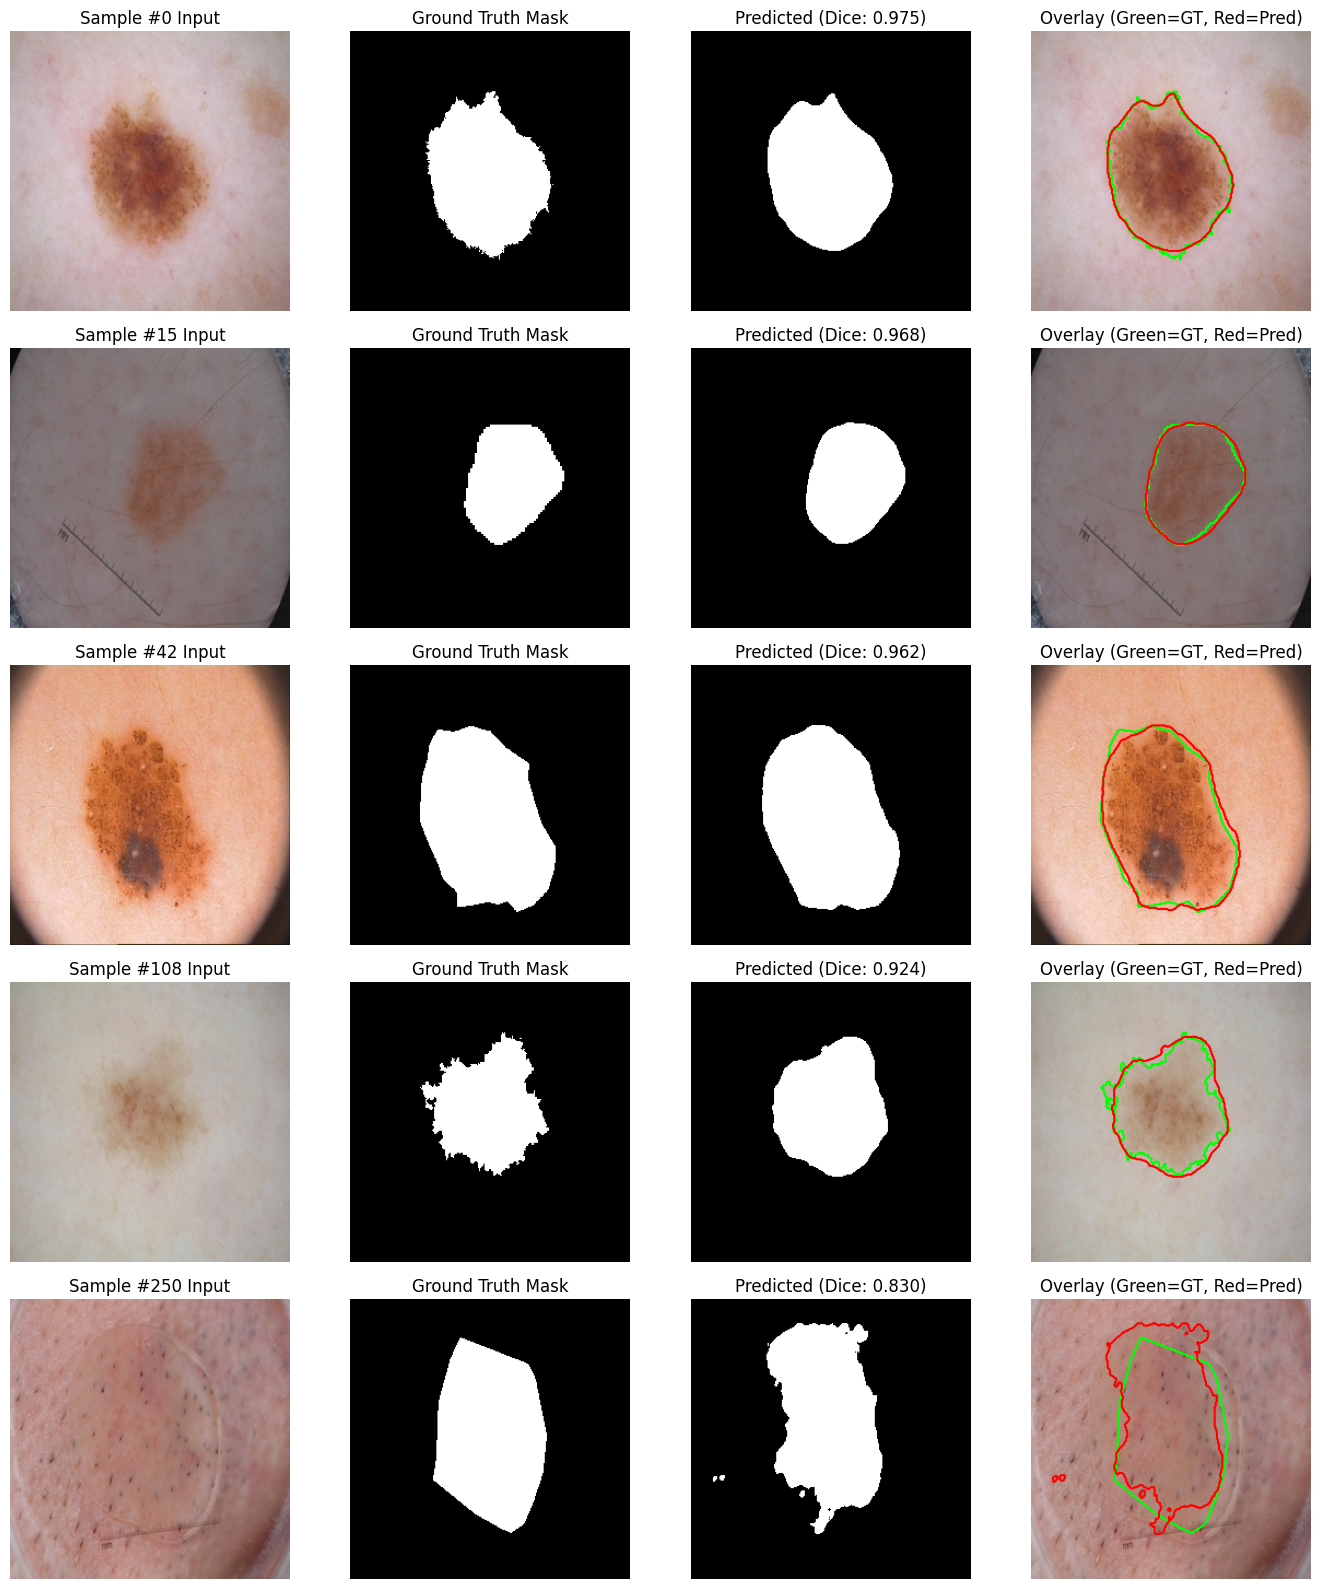

In [11]:
# FINAL EVAL

# =====================================================================
# FINAL EVALUATION & VISUAL QUALITATIVE RESULTS (BEST CHECKPOINT)
# =====================================================================
best_model = UNet(in_channels=3, out_channels=1).to(device)
best_model.load_state_dict(torch.load("best_isic_unet.pth", map_location=device))
best_model.eval()

dice_scores, iou_scores, acc_scores, sens_scores, spec_scores = [], [], [], [], []

with torch.no_grad():
    for imgs, msks in val_loader:
        imgs, msks = imgs.to(device), msks.to(device)
        preds = (torch.sigmoid(best_model(imgs)) > 0.5).float()

        for p, t in zip(preds, msks):
            tp = (p * t).sum().item()
            fp = (p * (1 - t)).sum().item()
            fn = ((1 - p) * t).sum().item()
            tn = ((1 - p) * (1 - t)).sum().item()

            dice_scores.append((2 * tp + 1e-5) / (2 * tp + fp + fn + 1e-5))
            iou_scores.append((tp + 1e-5) / (tp + fp + fn + 1e-5))
            acc_scores.append((tp + tn) / (tp + tn + fp + fn + 1e-5))
            sens_scores.append((tp + 1e-5) / (tp + fn + 1e-5))
            spec_scores.append((tn + 1e-5) / (tn + fp + 1e-5))

print("=" * 55)
print("FINAL VALIDATION METRICS (519 Unseen ISIC 2018 Images)")
print("=" * 55)
print(f"Mean Dice Coefficient (F1) : {np.mean(dice_scores):.4f} ± {np.std(dice_scores):.4f}")
print(f"Mean IoU (Jaccard Index)   : {np.mean(iou_scores):.4f} ± {np.std(iou_scores):.4f}")
print(f"Pixel Accuracy             : {np.mean(acc_scores):.4f}")
print(f"Sensitivity (Recall)       : {np.mean(sens_scores):.4f}")
print(f"Specificity                : {np.mean(spec_scores):.4f}")
print("=" * 55)

# Plot 5 sample predictions: Input | Ground Truth | Predicted Mask | Overlay
sample_indices = [0, 15, 42, 108, 250]
fig, axes = plt.subplots(len(sample_indices), 4, figsize=(14, 3.2 * len(sample_indices)))

with torch.no_grad():
    for row, idx in enumerate(sample_indices):
        img_t, msk_t = val_X[idx:idx+1].to(device), val_Y[idx, 0].cpu().numpy()
        pred_mask = (torch.sigmoid(best_model(img_t))[0, 0] > 0.5).float().cpu().numpy()
        img_np = val_X[idx].permute(1, 2, 0).cpu().numpy()

        # Overlay: Green = Ground Truth contour, Red = Predicted contour
        axes[row, 0].imshow(img_np)
        axes[row, 0].set_title(f"Sample #{idx} Input")
        axes[row, 0].axis("off")

        axes[row, 1].imshow(msk_t, cmap="gray")
        axes[row, 1].set_title("Ground Truth Mask")
        axes[row, 1].axis("off")

        axes[row, 2].imshow(pred_mask, cmap="gray")
        axes[row, 2].set_title(f"Predicted (Dice: {dice_scores[idx]:.3f})")
        axes[row, 2].axis("off")

        axes[row, 3].imshow(img_np)
        axes[row, 3].contour(msk_t, levels=[0.5], colors='lime', linewidths=1.5)
        axes[row, 3].contour(pred_mask, levels=[0.5], colors='red', linewidths=1.5)
        axes[row, 3].set_title("Overlay (Green=GT, Red=Pred)")
        axes[row, 3].axis("off")

plt.tight_layout()
plt.show()


Found 999 official unlabeled test images in Test_Input.
Inference complete on 999 test images in 159.0s (6.3 img/sec)!
Predicted masks saved to: E:\SCSU\SEM 03\541 - Neural Networks and Deep Learning\Assignments\Research Project\Code\dataset\ISIC2018_Task1_Test_Predictions
Average predicted lesion coverage: 28.29% ± 19.63%


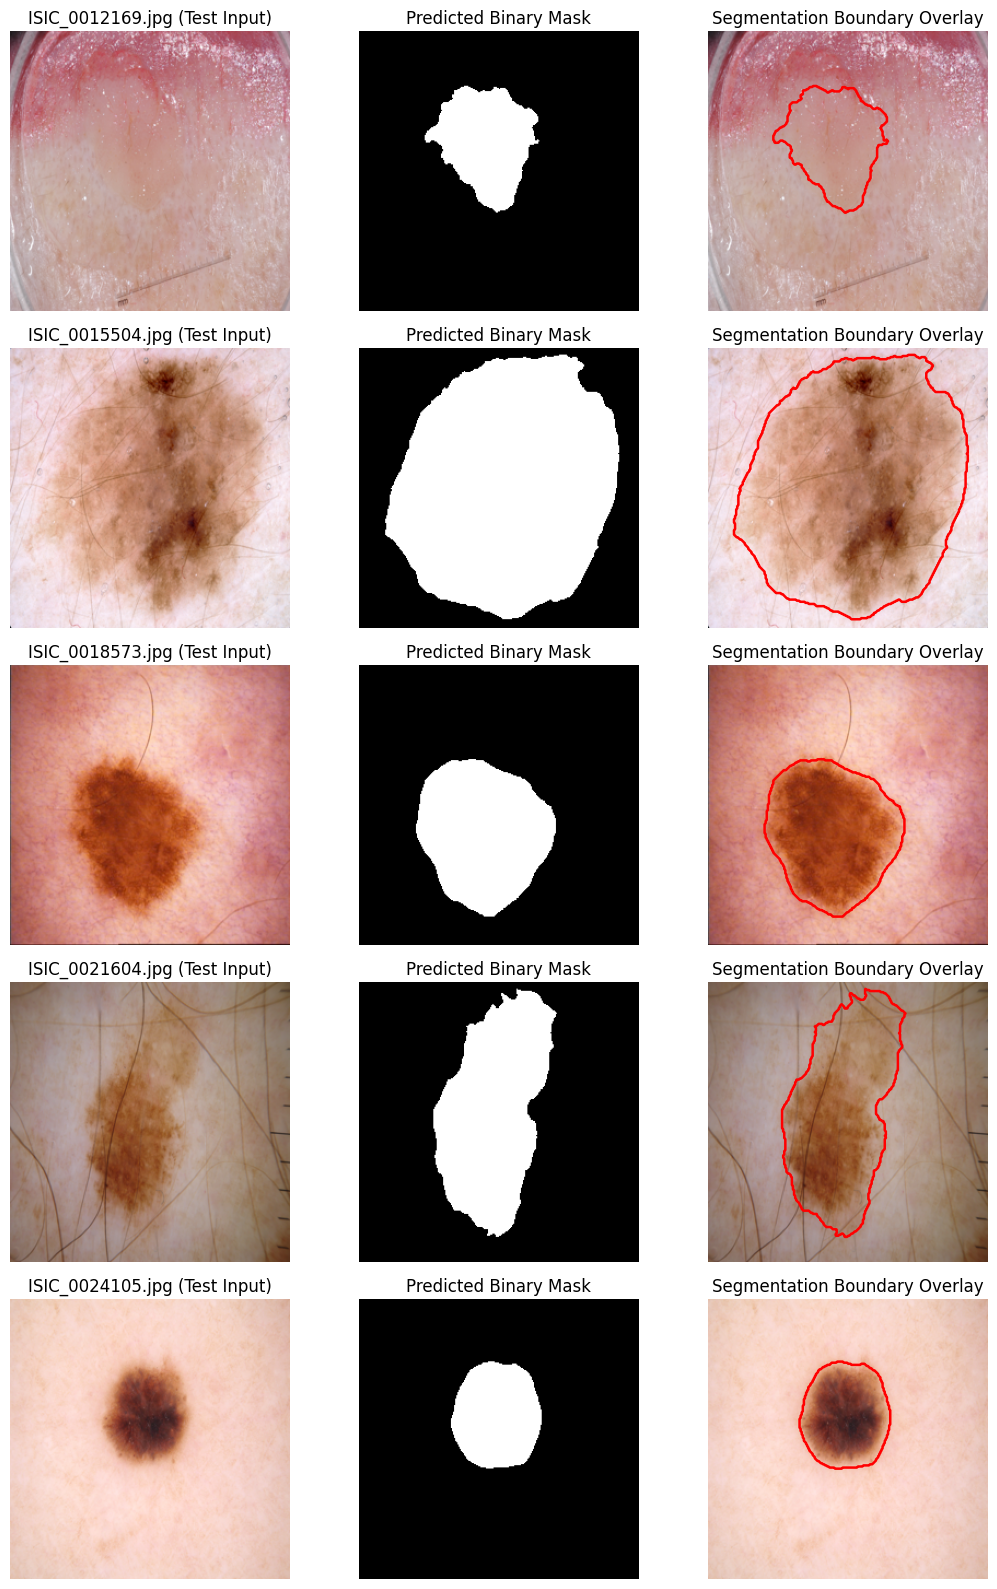

In [13]:
import time

# =====================================================================
# 1. SETUP TEST INPUT & PREDICTION OUTPUT DIRECTORIES
# =====================================================================
TEST_IMG_DIR = os.path.join(BASE_PATH, "ISIC2018_Task1-2_Test_Input")
PRED_OUT_DIR = os.path.join(BASE_PATH, "ISIC2018_Task1_Test_Predictions")
os.makedirs(PRED_OUT_DIR, exist_ok=True)

test_files = sorted([f for f in os.listdir(TEST_IMG_DIR) if f.endswith('.jpg')])
print(f"Found {len(test_files)} official unlabeled test images in Test_Input.")

# =====================================================================
# 2. LOAD BEST TRAINED U-NET CHECKPOINT
# =====================================================================
best_model = UNet(in_channels=3, out_channels=1).to(device)
best_model.load_state_dict(torch.load("best_isic_unet.pth", map_location=device))
best_model.eval()

# =====================================================================
# 3. RUN INFERENCE ACROSS ALL 1,000 TEST IMAGES & SAVE MASKS
# =====================================================================
t_start = time.time()
lesion_area_ratios = []
visual_samples = []  # Store first 5 for plotting

with torch.no_grad():
    for idx, fname in enumerate(test_files):
        img_path = os.path.join(TEST_IMG_DIR, fname)
        orig_img = Image.open(img_path).convert('RGB')
        orig_w, orig_h = orig_img.size

        # Preprocess to 256x256 tensor
        resized_img = orig_img.resize(IMG_SIZE)
        img_np = np.array(resized_img, dtype=np.float32) / 255.0
        img_tensor = torch.from_numpy(img_np).permute(2, 0, 1).unsqueeze(0).to(device)

        # Forward pass with AMP
        with torch.amp.autocast('cuda'):
            logits = best_model(img_tensor)
            pred_prob = torch.sigmoid(logits)[0, 0].cpu().numpy()

        pred_mask_256 = (pred_prob > 0.5).astype(np.uint8) * 255
        lesion_area_ratios.append((pred_mask_256 > 0).mean() * 100.0)

        # Resize predicted mask back to original image resolution & save as PNG
        mask_pil = Image.fromarray(pred_mask_256, mode='L').resize((orig_w, orig_h), resample=Image.NEAREST)
        out_name = fname.replace('.jpg', '_segmentation.png')
        mask_pil.save(os.path.join(PRED_OUT_DIR, out_name))

        # Keep 5 diverse examples (indices 0, 100, 250, 500, 750) for visualization
        if idx in (0, 100, 250, 500, 750):
            visual_samples.append((fname, img_np, (pred_mask_256 > 0).astype(np.float32)))

elapsed = time.time() - t_start
print(f"Inference complete on {len(test_files)} test images in {elapsed:.1f}s ({len(test_files)/elapsed:.1f} img/sec)!")
print(f"Predicted masks saved to: {PRED_OUT_DIR}")
print(f"Average predicted lesion coverage: {np.mean(lesion_area_ratios):.2f}% ± {np.std(lesion_area_ratios):.2f}%")

# =====================================================================
# 4. VISUALIZE 5 TEST SET PREDICTIONS (300 DPI REPORT-READY FIGURE)
# =====================================================================
fig, axes = plt.subplots(len(visual_samples), 3, figsize=(11, 3.2 * len(visual_samples)))

for row, (fname, img_np, mask_256) in enumerate(visual_samples):
    axes[row, 0].imshow(img_np)
    axes[row, 0].set_title(f"{fname} (Test Input)")
    axes[row, 0].axis("off")

    axes[row, 1].imshow(mask_256, cmap="gray")
    axes[row, 1].set_title("Predicted Binary Mask")
    axes[row, 1].axis("off")

    axes[row, 2].imshow(img_np)
    axes[row, 2].contour(mask_256, levels=[0.5], colors='red', linewidths=1.8)
    axes[row, 2].set_title("Segmentation Boundary Overlay")
    axes[row, 2].axis("off")

plt.tight_layout()
plt.savefig("isic_test_predictions_grid.png", dpi=300, bbox_inches="tight")
plt.show()
